## Word Count Program - Performance testing

This notebook will provide an insight into the differences in runtimes for my Word Count program and how the performances and duration changes as more resources are used during the spark job.

All the spark jobs performed within these tests will be conducted over the 100gb Wikipedia XML Dataset. Using the `time spark-submit` command, I was able to gather the runtime of each of the jobs and insert the data I gathered into an excel sheet to present my findings. 

In [33]:
import pandas as pd

performanceData = pd.read_excel("FYP_performance_testing.xlsx", "WordCount performance - Cores")

performanceData


,num_executors,executor_cores,executor_memory,total_cores,runtime_seconds
0,2,2,4G,4,9136
1,4,2,4G,8,6155
2,4,3,4G,12,3625
3,4,4,4G,16,3119
4,5,4,4G,20,2403
5,8,3,4G,24,2228
6,7,4,4G,28,1718
7,8,4,4G,32,1383
8,9,4,4G,36,1276


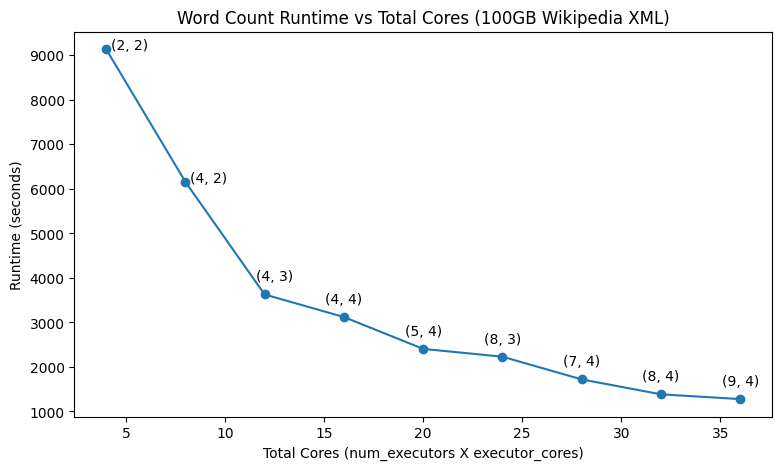

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))

plt.plot(performanceData["total_cores"],
         performanceData["runtime_seconds"],
         marker="o")

for i, row in performanceData.iterrows():
    label = f"({row['num_executors']}, {row['executor_cores']})"
    if row['total_cores'] > 15:
        plt.annotate(
            label,
            (row['total_cores'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(0,10),
            ha='center'
        )
    elif row['total_cores'] == 12:
        plt.annotate(
            label,
            (row['total_cores'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(7,10),
            ha='center'
        )
    else:
        plt.annotate(
            label,
            (row['total_cores'], row['runtime_seconds']),
            textcoords="offset points",
            xytext=(17,0),
            ha='center'
        )

plt.title("Word Count Runtime vs Total Cores (100GB Wikipedia XML)")
plt.xlabel("Total Cores (num_executors X executor_cores)")
plt.ylabel("Runtime (seconds)")

plt.show()

## Break Down of Results - total cores:

### Rapid Improvement - 4 -> 12 total cores:

- Runtime drops significantly
- Suggests that the workload is highly parallisable
- Adding cores distributes work evenly

### Slower Improvement - 12 -> 24 total cores:

- Since the server is one machine, split into different vms, not several different machines
- Could cause the non-linear pattern from continuing due to bottlenecks like the disk, network or shuffle subsystem.

### Diminishing Returns - 28 -> 36 total cores:

- This could be due to the server being one machine -> memory bandwidth is shared between the 'datanodes' as its split into various different VM's
- All the traffic is going through the same underlying network